In [34]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.metrics import log_loss

# PCA on iris Dataset

In [35]:
iris=pd.read_csv("D:\Machine Learning\Datasets\iris.csv")



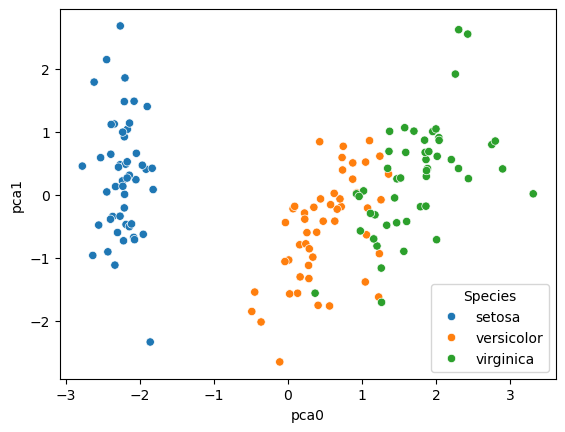

In [36]:


from matplotlib import pyplot as plt


X, y = iris.drop("Species", axis=1), iris["Species"]
scaler = StandardScaler().set_output(transform="pandas")
X_scaled = scaler.fit_transform(X)
prcomp = PCA().set_output(transform="pandas")
X_pca = prcomp.fit_transform(X_scaled)
X_pca
X_pca["Species"] = y
sns.scatterplot(data=X_pca, x="pca0", y="pca1", hue="Species")
plt.show()


In [37]:
X_pca

,pca0,pca1,pca2,pca3,Species
0,-2.264703,0.480027,0.127706,-0.024168,setosa
1,-2.080961,-0.674134,0.234609,-0.103007,setosa
2,-2.364229,-0.341908,-0.044201,-0.028377,setosa
3,-2.299384,-0.597395,-0.091290,0.065956,setosa
4,-2.389842,0.646835,-0.015738,0.035923,setosa
...,...,...,...,...,...
145,1.870503,0.386966,-0.256274,-0.389257,virginica
146,1.564580,-0.896687,0.026371,-0.220192,virginica
147,1.521170,0.269069,-0.180178,-0.119171,virginica
148,1.372788,1.011254,-0.933395,-0.026129,virginica


In [38]:
np.cumsum(prcomp.explained_variance_ratio_)*100

array([ 72.96244541,  95.8132072 ,  99.48212909, 100.        ])

use pca as feature 

In [39]:
X, y = iris.drop("Species", axis=1), iris["Species"]
X_train,y_train,X_test,y_test=train_test_split(X,y,test_size=.2,random_state=42)

In [40]:

from sklearn.linear_model import LogisticRegression

X, y = iris.drop("Species", axis=1), iris["Species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().set_output(transform="pandas")
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
prcomp = PCA().set_output(transform="pandas")
X_train_pca = prcomp.fit_transform(X_train_scaled)
X_test_pca = prcomp.transform(X_test_scaled)
# X_train_pca.iloc[:, :2]
lr = LogisticRegression()
lr.fit(X_train_pca.iloc[:, :2], y_train)
y_pred = lr.predict(X_test_pca.iloc[:, :2])

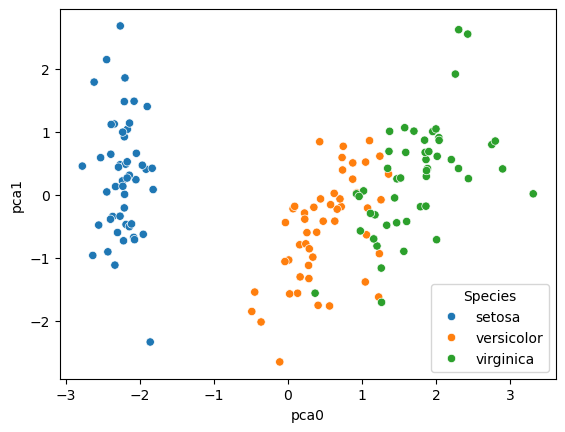

Log Loss: 0.2318315429693499
Accuracy: 0.9


array(['setosa', 'versicolor', 'versicolor', 'versicolor', 'setosa',
       'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor',
       'virginica', 'virginica', 'virginica', 'versicolor', 'setosa',
       'setosa', 'setosa', 'versicolor', 'versicolor', 'versicolor',
       'setosa', 'virginica', 'versicolor', 'virginica', 'virginica',
       'virginica', 'versicolor', 'setosa', 'virginica', 'setosa'],
      dtype=object)

In [44]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import os

X, y = iris.drop("Species", axis=1), iris["Species"]
scaler = StandardScaler().set_output(transform="pandas")
X_scaled = scaler.fit_transform(X)
prcomp = PCA().set_output(transform="pandas")
X_pca = prcomp.fit_transform(X_scaled)
X_pca["Species"] = y
sns.scatterplot(data=X_pca, x="pca0", y="pca1", hue="Species")
plt.show()
np.cumsum(prcomp.explained_variance_ratio_)*100
X, y = iris.drop("Species", axis=1), iris["Species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().set_output(transform="pandas")
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
prcomp = PCA().set_output(transform="pandas")
X_train_pca = prcomp.fit_transform(X_train_scaled)
X_test_pca = prcomp.transform(X_test_scaled)
# X_train_pca.iloc[:, :2]
lr = LogisticRegression()
lr.fit(X_train_pca.iloc[:, :2], y_train)
y_pred = lr.predict(X_test_pca.iloc[:, :2])
y_pred_proba = lr.predict_proba(X_test_pca.iloc[:, :2])
print(f"Log Loss: {log_loss(y_test, y_pred_proba)}")
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
y_pred

HR

In [45]:
hr=pd.read_csv("D:\Machine Learning\Datasets\HR_comma_sep.csv")

In [48]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder


X , y = hr.drop('left',axis=1) , hr['left']
ohe = OneHotEncoder(drop='first', sparse_output=False).set_output(transform="pandas")
col_transformer = ColumnTransformer([("OHE", ohe, make_column_selector(dtype_include=object))], 
                                    remainder='passthrough', 
                                    verbose_feature_names_out=False)
col_transformer = col_transformer.set_output(transform="pandas")
X = col_transformer.fit_transform(X)

in hr dataset there are various pca to consider

In [51]:

scaler = StandardScaler().set_output(transform="pandas")
X_scaled = scaler.fit_transform(X)
prcomp = PCA().set_output(transform="pandas")
X_pca = prcomp.fit_transform(X_scaled)
np.cumsum(prcomp.explained_variance_ratio_)*100


array([ 10.42723133,  20.58793491,  27.95567097,  34.76490283,
        41.43340638,  47.76274027,  53.86705251,  59.78971986,
        65.6726812 ,  71.52370417,  77.29664846,  82.69834762,
        87.55599268,  92.10660041,  95.62030665,  98.658159  ,
        99.46053041, 100.        ])

In [54]:
n_features=11
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().set_output(transform="pandas")
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
prcomp = PCA().set_output(transform="pandas")
X_train_pca = prcomp.fit_transform(X_train_scaled)
X_test_pca = prcomp.transform(X_test_scaled)
# X_train_pca.iloc[:, :2]
lr = LogisticRegression()
lr.fit(X_train_pca.iloc[:, :n_features], y_train)
y_pred = lr.predict(X_test_pca.iloc[:, :n_features])
y_pred_proba = lr.predict_proba(X_test_pca.iloc[:, :n_features])
print(f"Log Loss: {log_loss(y_test, y_pred_proba)}")
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
y_pred

Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454


array([0, 0, 0, ..., 0, 0, 0])

In [55]:
for n_feature in [9,10,11,12,13,14,15]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    X_train_pca = prcomp.fit_transform(X_train_scaled)
    X_test_pca = prcomp.transform(X_test_scaled)
    # X_train_pca.iloc[:, :2]
    
    lr.fit(X_train_pca.iloc[:, :n_features], y_train)
    y_pred = lr.predict(X_test_pca.iloc[:, :n_features])
    y_pred_proba = lr.predict_proba(X_test_pca.iloc[:, :n_features])
    print('No. of Components: ',n_feature)
    print(f"Log Loss: {log_loss(y_test, y_pred_proba)}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
    

No. of Components:  9
Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454
No. of Components:  10
Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454
No. of Components:  11
Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454
No. of Components:  12
Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454
No. of Components:  13
Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454
No. of Components:  14
Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454
No. of Components:  15
Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454


# Using pipelines

In [56]:
from sklearn.pipeline import Pipeline


alternative to iloc


In [59]:
prcomp=PCA(n_components=7).set_output(transform='pandas')
X_pca=prcomp.fit_transform(X)
X_pca

,pca0,pca1,pca2,pca3,pca4,pca5,pca6
0,-44.068128,-0.691488,-1.209055,0.677892,0.734702,0.119465,-0.157807
1,60.967993,2.355547,-0.090315,-0.697220,0.748873,0.099704,-0.118011
2,45.971630,0.789614,1.575359,0.688731,0.771808,0.094385,-0.164700
3,57.964357,1.386253,0.215808,0.695116,0.747477,0.092359,-0.101249
4,22.966658,1.613561,0.533332,0.695747,0.747671,0.092587,-0.104841
...,...,...,...,...,...,...,...
14990,-50.067722,-0.664197,-1.139723,0.670182,-0.359275,-0.713608,-0.198547
14991,-41.068369,-0.722626,-1.221966,0.670702,-0.359031,-0.712944,-0.200766
14992,-58.067280,-0.612883,-1.068837,0.670721,-0.358720,-0.712842,-0.201401
14993,78.969847,0.569415,1.301878,0.681320,-0.324955,-0.740490,-0.204142


In [60]:
prcomp=PCA(n_components=3).set_output(transform='pandas')
X_pca=prcomp.fit_transform(X)
X_pca

,pca0,pca1,pca2
0,-44.068128,-0.691488,-1.209055
1,60.967993,2.355547,-0.090315
2,45.971630,0.789614,1.575359
3,57.964357,1.386253,0.215808
4,22.966658,1.613561,0.533332
...,...,...,...
14990,-50.067722,-0.664197,-1.139723
14991,-41.068369,-0.722626,-1.221966
14992,-58.067280,-0.612883,-1.068837
14993,78.969847,0.569415,1.301878


In [58]:
for n_feature in [9,10,11,12,13,14,15]:
    prcomp=PCA(n_components=n_feature).set_output(transform='pandas')
    pipe=Pipeline([("SCL",scaler),('PCA',prcomp),("Lr",lr)])
    pipe.fit(X_train,y_train)
    y_pred_proba = pipe.predict_proba(X_test)
    print('No. of Components: ',n_feature)
    print(f"Log Loss: {log_loss(y_test, y_pred_proba)}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
    

No. of Components:  9
Log Loss: 0.46108111511724326
Accuracy: 0.7759253084361454
No. of Components:  10
Log Loss: 0.4610688691479803
Accuracy: 0.7759253084361454
No. of Components:  11
Log Loss: 0.45684954662656185
Accuracy: 0.7759253084361454
No. of Components:  12
Log Loss: 0.45522208809247744
Accuracy: 0.7759253084361454
No. of Components:  13
Log Loss: 0.4554215647587755
Accuracy: 0.7759253084361454
No. of Components:  14
Log Loss: 0.45349684143691854
Accuracy: 0.7759253084361454
No. of Components:  15
Log Loss: 0.45376738318538334
Accuracy: 0.7759253084361454


In [62]:


X_scaled = scaler.fit_transform(X)
prcomp = PCA().set_output(transform="pandas")
X_pca = prcomp.fit_transform(X_scaled)
np.cumsum(prcomp.explained_variance_ratio_)*100

array([ 10.42723133,  20.58793491,  27.95567097,  34.76490283,
        41.43340638,  47.76274027,  53.86705251,  59.78971986,
        65.6726812 ,  71.52370417,  77.29664846,  82.69834762,
        87.55599268,  92.10660041,  95.62030665,  98.658159  ,
        99.46053041, 100.        ])

use percentage over number of columns

In [69]:
np.linspace(.5,.95,10)

array([0.5 , 0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95])

In [ ]:

X_scaled = scaler.fit_transform(X)
prcomp = PCA(n_components=.5).set_output(transform="pandas")#.5 is 50 percentage
X_pca = prcomp.fit_transform(X_scaled)
np.cumsum(prcomp.explained_variance_ratio_)*100

array([10.42723133, 20.58793491, 27.95567097, 34.76490283, 41.43340638,
       47.76274027, 53.86705251])

In [66]:

X_scaled = scaler.fit_transform(X)
prcomp = PCA(n_components=.6).set_output(transform="pandas")#.6 is 60 percentage
X_pca = prcomp.fit_transform(X_scaled)
np.cumsum(prcomp.explained_variance_ratio_)*100

array([10.42723133, 20.58793491, 27.95567097, 34.76490283, 41.43340638,
       47.76274027, 53.86705251, 59.78971986, 65.6726812 ])

In [89]:
scores=[]
for percent_feature in np.linspace(.5,.95,10):#percentage colums from 50% from 
    prcomp=PCA(n_components=percent_feature).set_output(transform='pandas')
    pipe=Pipeline([("SCL",scaler),('PCA',prcomp),("Lr",lr)])
    pipe.fit(X_train,y_train)
    y_pred_proba = pipe.predict_proba(X_test)
    scores.append([percent_feature,log_loss(y_test, y_pred_proba)*100,accuracy_score(y_test, y_pred)*100])
per_feat_df=pd.DataFrame(scores,columns=('percentage_feature','log_loss_score','accuracy_score'))
per_feat_df=per_feat_df.sort_values('log_loss_score')
per_feat_df
pipe

Pipeline(steps=[('SCL', StandardScaler()),
                ('PCA', PCA(n_components=np.float64(0.95))),
                ('Lr', LogisticRegression())])

In [88]:
# Get the row with minimum log_loss_score
min_row = per_feat_df.loc[per_feat_df['log_loss_score'].idxmin()]
# Print only the percentage_feature value
print(min_row['percentage_feature']*100)


89.99999999999999
